# GOBAI: the oxygen minimum zone of the eastern tropical North Pacific

<a href="https://colab.research.google.com/github/ocean-icechunks/2026-ioos-hackathon/blob/main/examples/06-gobai-oxygen-minimum-zone.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"></a>

Map the oxygen minimum zone off Mexico and Central America, and track how far it reaches,
every week from 1993 to 2025, from NOAA's
[GOBAI HR](https://storage.googleapis.com/noaa-oar-gobai/index.html) (Gridded Ocean
Biogeochemistry from Artificial Intelligence): dissolved oxygen on a ¼° grid, 58 pressure
levels, weekly.

The product is 1,719 weekly fields per variable, in netCDF files of 1.4–7.3 GB each on
Google Cloud. The virtual Icechunk store makes them one dataset. No credentials needed.

## The textbook idea

Below the sunlit surface, bacteria use up oxygen as they break down sinking organic matter,
and only circulation brings more. In the eastern tropical Pacific, high productivity at the
surface meets slow, old water at depth, and oxygen at a few hundred metres falls almost to
zero: an **oxygen minimum zone** (OMZ). Below about **60 µmol/kg** (≈ 2 mg/L) many fish and
invertebrates are stressed (**hypoxic**); below about **20 µmol/kg** most animals cannot live.
Tropical OMZs have expanded over recent decades
([Stramma et al. 2008](https://doi.org/10.1126/science.1153847)).

GOBAI HR is **preliminary**, and it is a machine-learning estimate from temperature, salinity
and sparse oxygen observations, not a measurement at each point.

In [ ]:
%pip install -q "icechunk>=2.3" "xarray>=2026.7" "zarr>=3.4" matplotlib

## Open the dataset

In [2]:
import time
import icechunk as ic, xarray as xr, zarr
import numpy as np, matplotlib.pyplot as plt

zarr.config.set({"async.concurrency": 64})

SRC = "gs://noaa-oar-gobai/netcdf/v202606/"   # where the netCDF files, and so the data, live
repo = ic.Repository.open(
    ic.gcs_storage(bucket="noaa-oar-gobai", prefix="icechunk/v202606", anonymous=True),
    authorize_virtual_chunk_access=ic.containers_credentials({SRC: ic.gcs_credentials(anonymous=True)}),
)
ds = xr.open_zarr(repo.readonly_session("main").store, consolidated=False, chunks=None)
ds

<xarray.Dataset> Size: 827GB
Dimensions:             (time: 1719, mean_pressure: 58, latitude: 720,
                         longitude: 1440, vertices: 2)
Coordinates:
  * time                (time) datetime64[ns] 14kB 1993-01-01 ... 2025-12-05
  * mean_pressure       (mean_pressure) float32 232B 2.5 10.0 ... 1.975e+03
  * latitude            (latitude) float32 3kB -89.88 -89.62 ... 89.62 89.88
  * longitude           (longitude) float32 6kB 0.125 0.375 ... 359.6 359.9
    mean_pressure_bnds  (mean_pressure, vertices) float32 464B ...
Dimensions without coordinates: vertices
Data variables:
    no3                 (time, mean_pressure, latitude, longitude) float32 413GB ...
    o2                  (time, mean_pressure, latitude, longitude) float32 413GB ...
Attributes:
    title:                     GOBAI HR-v1.0 gridded oxygen and nitrate
    summary:                   GOBAI HR-v1.0 weekly gridded dissolved oxygen ...
    institution:               NOAA PMEL, CIMAR
    Conventions:               CF-1.10, ACDD-1.3
    source:                    gs://noaa-oar-gobai/netcdf/v202606/
    time_coverage_start:       1993-01-01
    time_coverage_end:         2025-12-05
    time_coverage_resolution:  P7D
    history:                   2026-09-04T23:19:38Z: virtual Icechunk store b...

Nothing has been read yet but metadata, and xarray already knows how much data it can reach:

In [ ]:
print(f"Size reported by xarray: {ds.nbytes / 1e9:,.0f} GB")

Size reported by xarray: 827 GB


## Read 33 years at 300 dbar

Every week from 1993 to 2025, one pressure level (300 dbar, about 300 m), 5 °S–40 °N and
160–75 °W. The store's chunks are 100 weeks × one level × a 45° tile, so this is about 100
chunks; it took about a minute on a JupyterHub in AWS, and should be faster on Colab, which
runs in Google Cloud next to the data.

In [3]:
o2 = ds.o2.sel(mean_pressure=300, latitude=slice(-5, 40), longitude=slice(200, 285))
o2 = o2.assign_coords(longitude=o2.longitude - 360)        # 0–360 to −180–180

start = time.time()
o2 = o2.load()
print(f"{o2.time.size:,} weeks read in {time.time() - start:.0f} s")

1,719 weeks read in 6 s


## Map: mean oxygen at 300 dbar

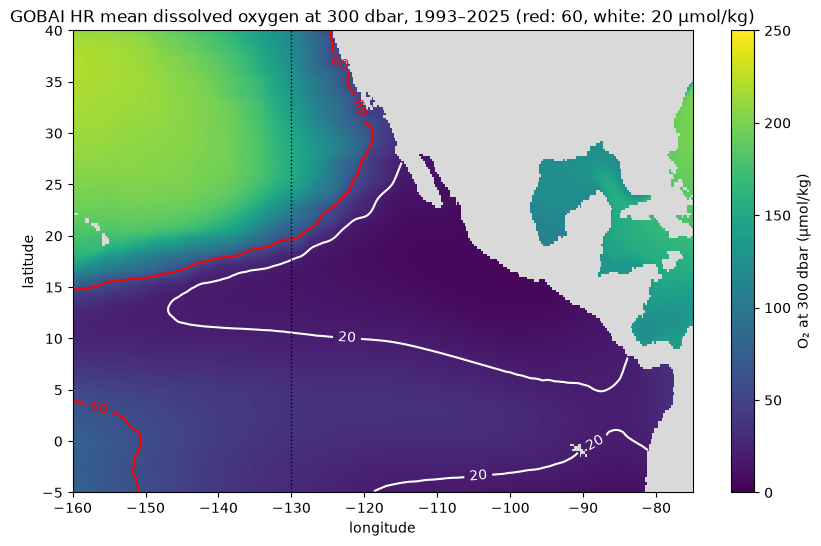

In [4]:
mean = o2.mean("time")

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_facecolor("0.85")                                     # land
mean.plot(ax=ax, cmap="viridis", vmin=0, vmax=250, cbar_kwargs={"label": "O₂ at 300 dbar (µmol/kg)"})
cs = mean.plot.contour(ax=ax, levels=[20, 60], colors=["w", "r"], linewidths=1.5)
ax.clabel(cs, fmt="%d")
ax.axvline(-130, color="k", ls=":", lw=1)
ax.set(title="GOBAI HR mean dissolved oxygen at 300 dbar, 1993–2025 (red: 60, white: 20 µmol/kg)",
       xlabel="longitude", ylabel="latitude")
plt.show()

The white 20 µmol/kg line encloses the core of the zone, a tongue reaching west from Mexico
and Central America to about 145 °W; the northern edge of its southern
counterpart, off Peru, shows at the bottom. The
red 60 µmol/kg line, the edge of hypoxic water, runs much further north along the coast, up
Baja California and California, where the California Undercurrent carries low-oxygen water
poleward.

## Extent through time

Two measures, one value per week, averaged by year: the **area** below 60 µmol/kg in the box,
and the **northern edge** of that water along 130 °W (the dotted line on the map), far enough
offshore that the coast does not get in the way.

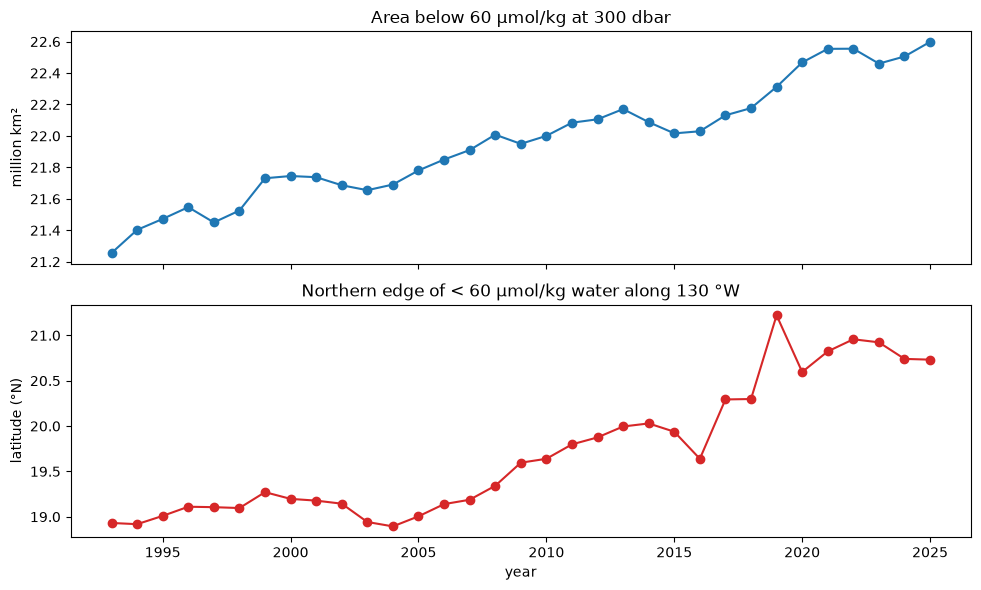

In [5]:
cell_km2 = (111.32 * 0.25) ** 2 * np.cos(np.deg2rad(o2.latitude))   # ¼° cells shrink toward the pole
hypoxic = o2 < 60
area = (hypoxic * cell_km2).sum(["latitude", "longitude"]) / 1e6        # million km²
edge = o2.latitude.where(hypoxic.sel(longitude=-130, method="nearest")).max("latitude")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
area.groupby("time.year").mean().plot(ax=ax1, marker="o")
ax1.set(xlabel="", ylabel="million km²", title="Area below 60 µmol/kg at 300 dbar")
edge.groupby("time.year").mean().plot(ax=ax2, marker="o", color="tab:red")
ax2.set(xlabel="year", ylabel="latitude (°N)", title="Northern edge of < 60 µmol/kg water along 130 °W")
plt.tight_layout()
plt.show()

In GOBAI, the area below 60 µmol/kg at 300 dbar grew from 21.3 to 22.6 million km² (about 6 %)
between 1993 and 2025, and along 130 °W its northern edge moved from about 18.9 °N to 20.7 °N,
roughly 200 km. That is the direction of the expansion Stramma et al. reported. But GOBAI HR is
preliminary, and oxygen observations were sparse in the early years, so treat this as something
to check against observations, not as a result.

**More:** the [GOBAI page](https://storage.googleapis.com/noaa-oar-gobai/index.html) has the
viewer, ERDDAP access and how to cite GOBAI; GOBAI HR has no citable release yet.